<a href="https://colab.research.google.com/github/sofiiamyshelova-prog/python_for_ds_tasks/blob/main/Copy_of_LSTM_%D0%B4%D0%BB%D1%8F_%D0%BF%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Давайте подивимося, як LSTM можна використовувати для побудови нейронної мережі прогнозування часових.

Будемо працювати з задачею прогнозування кількості пасажирів міжнародних авіаліній. З цим набором даних ми вже працювали в лекції "Time Series Analysis" і ви зможете порівняти результати :)

Задача полягає в тому, щоб за заданими роком і місяцем передбачити кількість пасажирів міжнародних авіаліній в одиницях виміру 1,000. Дані охоплюють період з січня 1949 року по грудень 1960 року, тобто 12 років, зі 144 спостереженнями.

Це регресійна задача. Тобто, знаючи кількість пасажирів (в тисячах) за останні місяці, можна передбачити, якою буде кількість пасажирів у наступному місяці. Набір даних має лише одну характеристику: "Кількість пасажирів" - `Passengers`.

Далі вже наведений код для читання даних, але нам їх ще треба буде трошки обробити.

In [67]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# Завантаження даних
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)
df.set_index('Month', inplace=True)
display(df.head())

,Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121


**Завдання 1.** Створіть змінну типу `numpy.ndarray`, яка містить значення кількості пасажирів в форматі `float32`. Такий формат даних нам треба для тренування нейромережі.

In [68]:
# Створюємо numpy.ndarray типу float32
passengers = df['Passengers'].values.astype(np.float32)

print(passengers[:10])
print(type(passengers))
print(passengers.dtype)

[112. 118. 132. 129. 121. 135. 148. 148. 136. 119.]
<class 'numpy.ndarray'>
float32


Очікуваний результат:
```array([112., 118., 132., 129., 121.], dtype=float32)```

**Завдання 2**. Розбийте дані на тренувальні і валідаційні у співвідношенні 67% йде у тренування, 33 - у валідацію. Памʼятаємо, що ми працюємо з tim series, відповідно, навчаємось на давніших, валідуємось - на новіших.

In [69]:
# Розділяємо дані без перемішування, зберігаючи часовий порядок
train_size = int(len(passengers) * 0.67)

train = passengers[:train_size]
test = passengers[train_size:]

print("Train shape:", train.shape)
print("Validation shape:", test.shape)

Train shape: (96,)
Validation shape: (48,)


**Завдання 3**.

Реалізуйте функцію `create_dataset`, яка перетворить одномірний часовий ряд (набір даних) у формат, придатний для тренування нейромережі.

Функція повинна приймати два аргументи:
- `dataset` — numpy-масив часового ряду,
- `lookback` — кількість попередніх кроків, які використовуватимуться для передбачення.

Функція повинна повернути два **тензори** PyTorch:
- `X` — набір ознак (вікно попередніх значень),
- `y` — цільові значення (наступні після вікна кроки).

Дані ми будемо подавати моделі в наступному форматі:
`
tensor([[112.],
        [118.],
        [132.],
        [129.],
        [121.]])
`
Відповідно першою розмірністю буде йти розмір вхідного батча, а другою - розмір вхіднизх даних і в нас це 1, бо лише одне значення на вході щоразу.

Після виконання завдання запустіть код нижче. Ми будемо передбачати на основі кількості пасажирів в попередній день кількість пасажирів в наступний, тому `lookback == 1`.

In [70]:
import torch

def create_dataset(dataset, lookback):
    X, y = [], []

    for i in range(len(dataset) - lookback):
        feature = dataset[i:i + lookback]
        target = dataset[i + lookback]

        X.append(feature)
        y.append(target)

    X = torch.tensor(np.array(X), dtype=torch.float32)
    y = torch.tensor(np.array(y), dtype=torch.float32)

    return X, y

In [72]:
lookback = 1
X_train, y_train = create_dataset(train, lookback=lookback)
X_test, y_test = create_dataset(test, lookback=lookback)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([95, 1]) torch.Size([95])
torch.Size([47, 1]) torch.Size([47])


Очікуваний результат:
```
torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])
```

**Завдання 4**.

Зверніть увагу на розмірності в попередньому завданні. Ми
З допомогою модуля `torch.nn` опишіть клас `AirModel`, який є нейронною мережею для прогнозування кількості пасажирів за допомогою LSTM.

1. **Конструктор класу** повинен приймати параметри `hidden_size`, `num_layers` та ініціювати шари:
   - LSTM-шар з наступними параметрами:
     - `input_size` — кожна точка часового ряду є окремим входом,,
     - `hidden_size` — заданий в конструкторі класу мережі,
     - `num_layers=1` — кількість шарів LSTM, задана в конструкторі мережі,
     - `batch_first=True` — визначає, що першим виміром є розмір батчу.
   - Лінійний шар (`nn.Linear`) для перетворення виходу LSTM на прогноз однієї точки.

2. **Метод forward** повинен виконувати наступні дії:
   - Передати вхідний тензор через LSTM-шар і отримати виходи (ігноруючи приховані стани).
   - Пропустити вихід LSTM через лінійний шар для отримання остаточного прогнозу.

Створіть об'єкт класу `AirModel` зі значеннями параметрів `hidden_size=50`, `num_layers=1` і протестуйте роботу моделі на вхідному тензорі `tensor([[112.]])`. На цьому етапі ми маємо переконатись, що модель здатна генерувати передбачення з рандомно ініційованими вагами.

In [73]:
import torch.nn as nn

class AirModel(nn.Module):
    def __init__(self, hidden_size, num_layers):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.linear = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.linear(out)
        return out



In [74]:
model = AirModel(hidden_size=50, num_layers=1)

x = torch.tensor([[[112.]]])

prediction = model(x)

print("Prediction:", prediction)
print("Output shape:", prediction.shape)

Prediction: tensor([[[-0.1397]]], grad_fn=<ViewBackward0>)
Output shape: torch.Size([1, 1, 1])


In [75]:
X_train = X_train.unsqueeze(-1)
X_test = X_test.unsqueeze(-1)

**Завдання 5**.

Створіть об'єкт DataLoader для завантаження даних, використовуючи тренувальні вибірки `X_train` та `y_train`. Ваш DataLoader повинен виконувати наступні вимоги:

1. Використовувати клас `TensorDataset`, щоб об'єднати тензори ознак `X_train` і цільових значень `y_train`.
2. Дані повинні завантажуватися невеликими батчами розміром 8 за допомогою параметра `batch_size`.
3. Використовувати параметр `shuffle=True`, щоб дані перемішувалися перед кожною епохою тренування.


In [76]:
from torch.utils.data import TensorDataset, DataLoader

# Об'єднуємо ознаки та цільові значення
train_dataset = TensorDataset(X_train, y_train)

# Створюємо DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

In [77]:
# Перевіряємо один батч
X_batch, y_batch = next(iter(train_loader))

print("X_batch shape:", X_batch.shape)
print("y_batch shape:", y_batch.shape)
print("X_batch:", X_batch)
print("y_batch:", y_batch)

X_batch shape: torch.Size([8, 1, 1])
y_batch shape: torch.Size([8])
X_batch: tensor([[[235.]],

        [[196.]],

        [[188.]],

        [[136.]],

        [[413.]],

        [[145.]],

        [[150.]],

        [[135.]]])
y_batch: tensor([229., 236., 235., 119., 405., 150., 178., 148.])


In [78]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: torch.Size([95, 1, 1])
X_test: torch.Size([47, 1, 1])
y_train: torch.Size([95])
y_test: torch.Size([47])


**Завдання 6**.

1. Реалізуйте навчання нейронної мережі `AirModel` для прогнозування часових рядів, використовуючи Adam-оптимізатор та функцію втрат MSE (середньоквадратичну похибку).
2. Створіть цикл тренування для 2000 епох, у якому на кожній епосі:
   - Виконуйте крок тренування моделі (прямий прохід, обчислення похибки, зворотний прохід і оновлення ваг).
   - Підраховуйте середню похибку на кожному батчі даних і зберігайте її у списку `losses`.
3. Раз на 100 епох проводьте валідацію моделі:
   - Перевіряйте модель на тренувальних та тестових даних без оновлення ваг.
   - Обчислюйте корінь середньоквадратичної похибки (RMSE) для тренувальної та тестової вибірок і виводьте результати на екран.
   
**Примітка:**
- Використовуйте вже створений `DataLoader` для отримання батчів даних.
- Валідацію виконуйте в режимі `eval()`, вимикаючи обчислення градієнтів з `torch.no_grad()`.

**Приклад виходу:**
```
Epoch 0: train RMSE 12.3456, test RMSE 15.6789
Epoch 100: train RMSE 9.8765, test RMSE 12.3456
...
```

In [79]:
# додаємо вимір ознак
if X_train.ndim == 2:
    X_train = X_train.unsqueeze(-1)

if X_test.ndim == 2:
    X_test = X_test.unsqueeze(-1)

# Створюємо DataLoader
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

# Ініціалізуємо модель, оптимізатор і функцію втрат
model = AirModel(hidden_size=50, num_layers=1)
optimizer = torch.optim.Adam(model.parameters())
loss_fn = nn.MSELoss()

losses = []

# Навчання протягом 2000 епох
for epoch in range(2000):
    model.train()
    epoch_losses = []

    for X_batch, y_batch in train_loader:
        # Прямий прохід
        y_pred = model(X_batch)

        # Приводимо цільові значення до форми прогнозів
        y_batch = y_batch.reshape_as(y_pred)

        # Обчислюємо MSE
        loss = loss_fn(y_pred, y_batch)

        # Зворотний прохід та оновлення ваг
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    # Зберігаємо середню втрату за епоху
    losses.append(np.mean(epoch_losses))

    # Валідація кожні 100 епох
    if epoch % 100 == 0:
        model.eval()

        with torch.no_grad():
            # Прогноз для тренувальної вибірки
            train_pred = model(X_train).reshape(-1)
            train_targets = y_train.reshape(-1)

            # Прогноз для валідаційної вибірки
            test_pred = model(X_test).reshape(-1)
            test_targets = y_test.reshape(-1)

            # Обчислюємо RMSE
            train_rmse = torch.sqrt(
                torch.mean((train_pred - train_targets) ** 2)
            ).item()

            test_rmse = torch.sqrt(
                torch.mean((test_pred - test_targets) ** 2)
            ).item()

        print(
            f"Epoch {epoch}: "
            f"train RMSE {train_rmse:.4f}, "
            f"test RMSE {test_rmse:.4f}"
        )

Epoch 0: train RMSE 225.5947, test RMSE 421.9642
Epoch 100: train RMSE 188.4527, test RMSE 383.1468
Epoch 200: train RMSE 157.6147, test RMSE 350.0439
Epoch 300: train RMSE 130.4048, test RMSE 319.5327
Epoch 400: train RMSE 107.2037, test RMSE 291.3833
Epoch 500: train RMSE 88.7983, test RMSE 265.9434
Epoch 600: train RMSE 72.2876, test RMSE 241.5833
Epoch 700: train RMSE 58.8509, test RMSE 218.7926
Epoch 800: train RMSE 48.7107, test RMSE 197.9640
Epoch 900: train RMSE 40.4845, test RMSE 179.3427
Epoch 1000: train RMSE 34.7127, test RMSE 163.1090
Epoch 1100: train RMSE 30.7823, test RMSE 149.4332
Epoch 1200: train RMSE 28.9525, test RMSE 137.6447
Epoch 1300: train RMSE 26.8499, test RMSE 128.4045
Epoch 1400: train RMSE 25.7241, test RMSE 121.9447
Epoch 1500: train RMSE 24.9001, test RMSE 116.6046
Epoch 1600: train RMSE 24.3146, test RMSE 111.5163
Epoch 1700: train RMSE 28.4589, test RMSE 107.3903
Epoch 1800: train RMSE 23.7807, test RMSE 105.4217
Epoch 1900: train RMSE 23.5324, test R

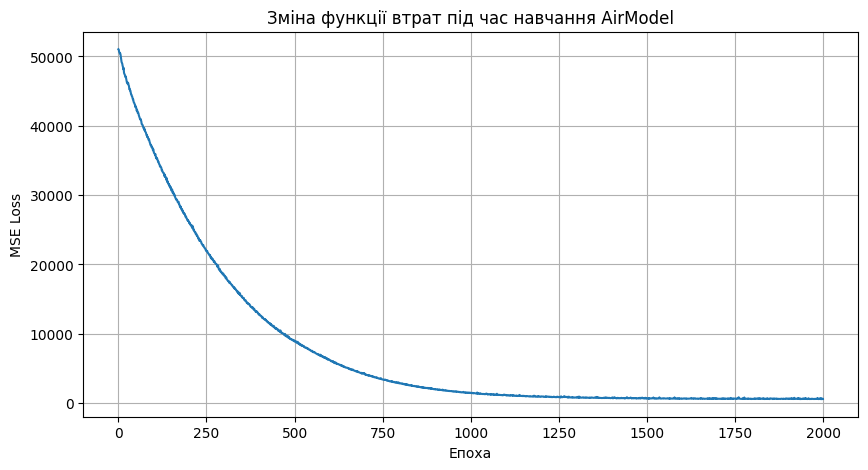

**Завдання 7.** Побудуйте графік лосів. Зробіть висновок з графіку, чи навчилась модель?

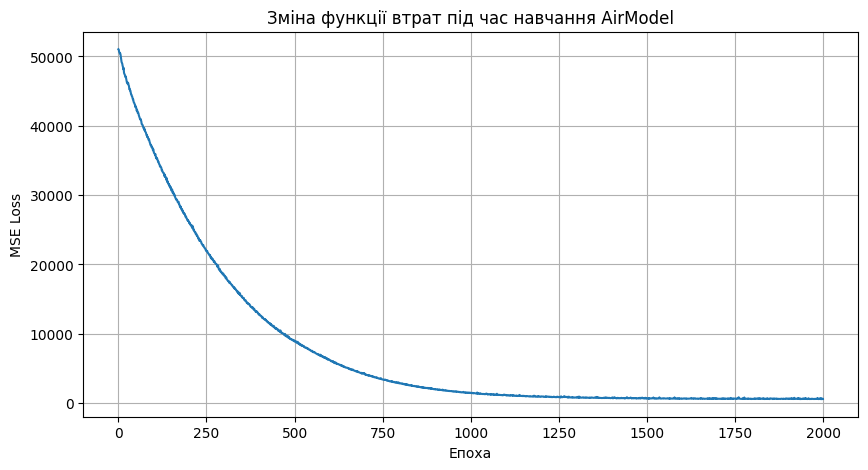

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(losses)
plt.xlabel("Епоха")
plt.ylabel("MSE Loss")
plt.title("Зміна функції втрат під час навчання AirModel")
plt.grid(True)
plt.show()

Модель навчилась, але не факт, що точно)

Доволі неочікувано, що середньоквадратичне відхилення тестового набору даних буде на порядок більшим за одиниці в нашому наборі даних. Середньоквадратичне відхилення 100 означає, що прогноз і фактичне значення будуть відрізнятися в середньому на 100 (тобто, 100 000 пасажирів у цьому наборі даних).



Щоб краще зрозуміти якість прогнозу, ви можете побудувати графік з кодом нижче (а ще нижче - описано, що відбувається в цьому коді, бо це теж корисно зрозуміти):

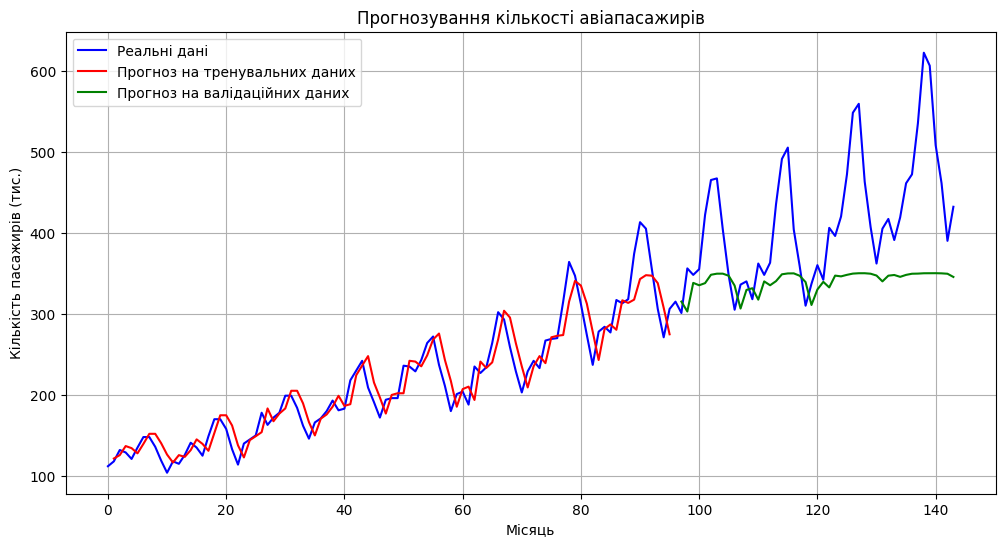

In [45]:
timeseries = passengers

def plot_predicts():
    model.eval()

    with torch.no_grad():
        # Масив для прогнозів на тренувальних даних
        train_plot = np.full(len(timeseries), np.nan)

        train_pred = model(X_train)[:, -1].reshape(-1).numpy()
        train_plot[lookback:train_size] = train_pred

        # Масив для прогнозів на валідаційних даних
        test_plot = np.full(len(timeseries), np.nan)

        test_pred = model(X_val)[:, -1].reshape(-1).numpy()
        test_plot[train_size + lookback:len(timeseries)] = test_pred

    # Візуалізація
    plt.figure(figsize=(12, 6))
    plt.plot(timeseries, c='b', label='Реальні дані')
    plt.plot(train_plot, c='r', label='Прогноз на тренувальних даних')
    plt.plot(test_plot, c='g', label='Прогноз на валідаційних даних')

    plt.xlabel('Місяць')
    plt.ylabel('Кількість пасажирів (тис.)')
    plt.title('Прогнозування кількості авіапасажирів')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_predicts()

**Що відбувається в коді вище.** В цьому коді здійснюється процес прогнозування часових рядів за допомогою LSTM моделі, а також виведення графіку, який показує реальні значення, тренувальні та тестові прогнози. Ось що відбувається на кожному етапі:

1. **`torch.no_grad()`**: Цей контекстний менеджер вимикає обчислення градієнтів, що означає, що під час прогнозування не будуть зберігатися проміжні обчислення для зворотного проходу (backpropagation). Це підвищує ефективність під час прогнозування і зменшує використання пам'яті.

2. **Зсув прогнозів для тренувальних даних:**
   - Створюється масив `train_plot`, який має такий самий розмір, як і часовий ряд (`timeseries`), і заповнюється значеннями NaN (`np.nan`), щоб залишити місце для реальних значень.
   - Модель передбачає виходи для тренувальних даних `X_train`.
   - Використовується лише останнє передбачене значення для кожного входу LSTM (`y_pred[:, -1]`).
   - Прогнози зсуваються, починаючи з індексу `lookback` до кінця тренувальних даних (індекс `train_size`). Цей зсув потрібен, щоб зробити прогноз на основі попередніх даних і відобразити його на правильній частині графіку.

3. **Зсув прогнозів для тестових даних:**
   - Створюється масив `test_plot`, який також заповнюється NaN.
   - Прогнози для тестових даних додаються з індексу `train_size + lookback` до кінця реальних даних, щоб відобразити, де модель починає прогнозувати тестову вибірку.

4. **Побудова графіка:**
   - `plt.plot(timeseries, c='b')`: Виводить реальні значення часового ряду (синя лінія).
   - `plt.plot(train_plot, c='r')`: Виводить тренувальні прогнози (червона лінія).
   - `plt.plot(test_plot, c='g')`: Виводить тестові прогнози (зелена лінія).

**Чому це робиться:**
- Зсув прогнозів для тренувальних і тестових даних дозволяє візуально зрівняти, наскільки добре модель прогнозує як на тренувальній, так і на тестовій вибірках. Зазвичай, червона лінія (тренувальні прогнози) повинна точно відповідати синій лінії (реальні дані), а зелена лінія (тестові прогнози) дає змогу побачити, наскільки модель добре працює на нових даних, яких вона раніше не бачила.

**Завдання 8**. Навчіть модель з hidden_size=100 та порівняйте результати прогнозів з попередніми.

In [46]:
import copy

model_50 = copy.deepcopy(model)

In [48]:
model_100 = AirModel(hidden_size=100, num_layers=1)

optimizer = torch.optim.Adam(model_100.parameters())
loss_fn = nn.MSELoss()

losses_100 = []

for epoch in range(2000):
    model_100.train()
    epoch_losses = []

    for X_batch, y_batch in train_loader:
        y_pred = model_100(X_batch)
        y_batch = y_batch.reshape_as(y_pred)

        loss = loss_fn(y_pred, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    losses_100.append(np.mean(epoch_losses))

    if epoch % 100 == 0:
        model_100.eval()

        with torch.no_grad():
            train_pred = model_100(X_train).reshape(-1)
            test_pred = model_100(X_test).reshape(-1)

            train_rmse = torch.sqrt(
                torch.mean((train_pred - y_train.reshape(-1)) ** 2)
            ).item()

            val_rmse = torch.sqrt(
                torch.mean((test_pred - y_test.reshape(-1)) ** 2)
            ).item()

        print(
            f"Epoch {epoch}: "
            f"train RMSE {train_rmse:.4f}, "
            f"test RMSE {test_rmse:.4f}"
        )

Epoch 0: train RMSE 225.8212, test RMSE 73.9698
Epoch 100: train RMSE 146.4456, test RMSE 73.9698
Epoch 200: train RMSE 97.8350, test RMSE 73.9698
Epoch 300: train RMSE 68.5909, test RMSE 73.9698
Epoch 400: train RMSE 48.9168, test RMSE 73.9698
Epoch 500: train RMSE 37.0393, test RMSE 73.9698
Epoch 600: train RMSE 31.3622, test RMSE 73.9698
Epoch 700: train RMSE 26.7004, test RMSE 73.9698
Epoch 800: train RMSE 25.0196, test RMSE 73.9698
Epoch 900: train RMSE 25.2828, test RMSE 73.9698
Epoch 1000: train RMSE 25.5585, test RMSE 73.9698
Epoch 1100: train RMSE 24.0001, test RMSE 73.9698
Epoch 1200: train RMSE 24.3604, test RMSE 73.9698
Epoch 1300: train RMSE 24.4336, test RMSE 73.9698
Epoch 1400: train RMSE 23.1608, test RMSE 73.9698
Epoch 1500: train RMSE 23.1855, test RMSE 73.9698
Epoch 1600: train RMSE 25.8559, test RMSE 73.9698
Epoch 1700: train RMSE 23.3705, test RMSE 73.9698
Epoch 1800: train RMSE 22.9080, test RMSE 73.9698
Epoch 1900: train RMSE 23.5612, test RMSE 73.9698


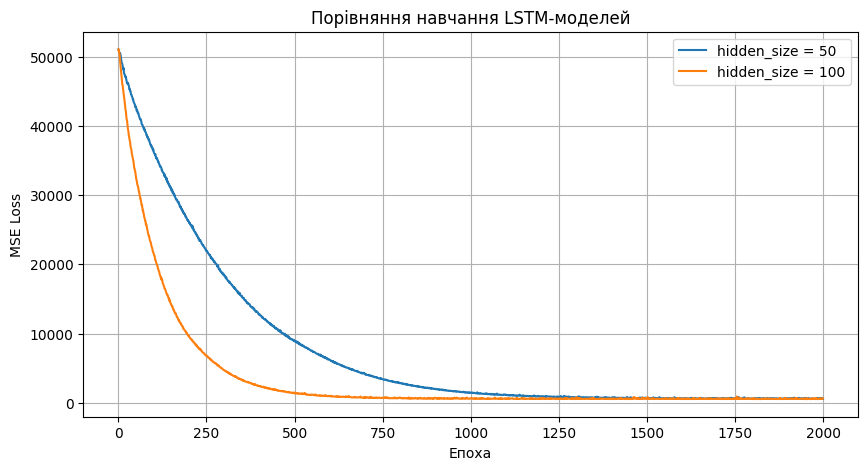

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(losses, label='hidden_size = 50')
plt.plot(losses_100, label='hidden_size = 100')

plt.xlabel('Епоха')
plt.ylabel('MSE Loss')
plt.title('Порівняння навчання LSTM-моделей')
plt.legend()
plt.grid(True)
plt.show()

In [50]:
def evaluate_model(model):
    model.eval()

    with torch.no_grad():
        train_pred = model(X_train).reshape(-1)
        val_pred = model(X_val).reshape(-1)

        train_rmse = torch.sqrt(
            torch.mean((train_pred - y_train.reshape(-1)) ** 2)
        ).item()

        val_rmse = torch.sqrt(
            torch.mean((val_pred - y_test.reshape(-1)) ** 2)
        ).item()

    return train_rmse, test_rmse


train_rmse_50, test_rmse_50 = evaluate_model(model_50)
train_rmse_100, test_rmse_100 = evaluate_model(model_100)

print(f"hidden_size=50:  train RMSE={train_rmse_50:.4f}, "
      f"validation RMSE={test_rmse_50:.4f}")

print(f"hidden_size=100: train RMSE={train_rmse_100:.4f}, "
      f"validation RMSE={test_rmse_100:.4f}")

hidden_size=50:  train RMSE=23.5530, validation RMSE=73.9698
hidden_size=100: train RMSE=23.6041, validation RMSE=73.9698


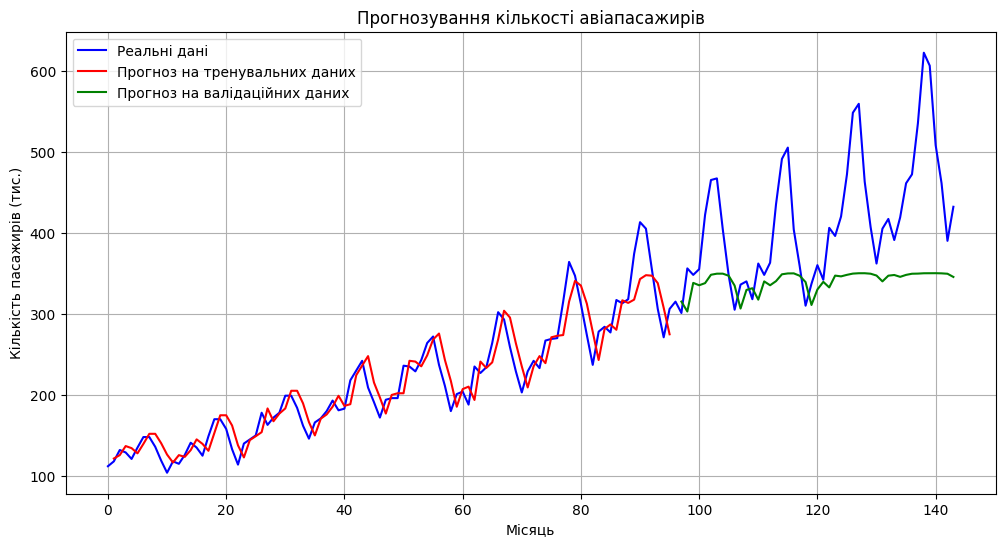

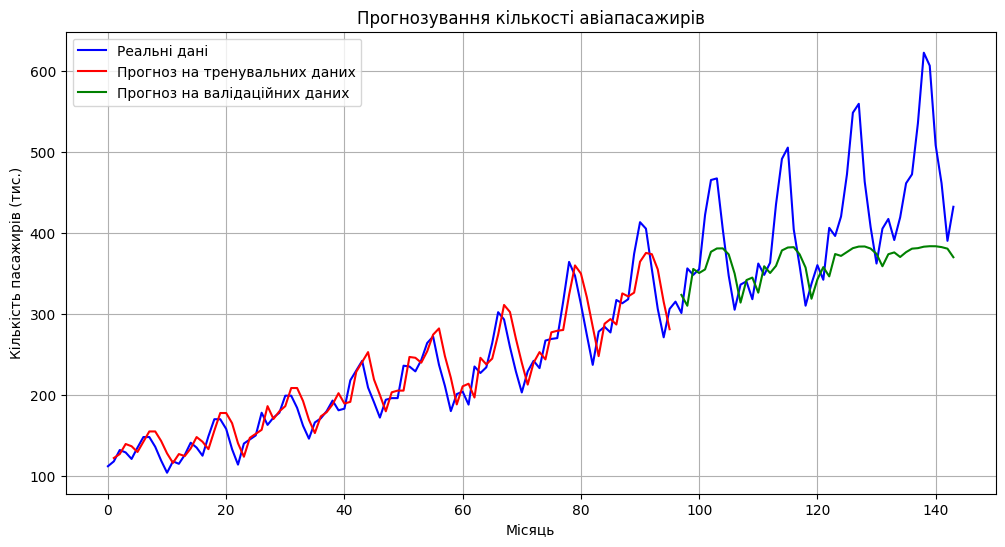

In [51]:
model = model_50
plot_predicts()

model = model_100
plot_predicts()

На графіку видно, що модель досить добре навчається на тренувальних даних, але на валідаційних прогнозує значно гірше.

Ми використовуємо lookback = 1, тобто модель отримує лише кількість пасажирів за попередній місяць. Цього недостатньо, щоб повноцінно виявити річну сезонність.